# Hybrid Sweep Workflows and Performance

:::{tip} Run interactively
Run this notebook interactively in your browser with zero installation:
- **[Open in JupyterLite Lab](/lite/lab/index.html?path=user-guide/sweep/backends.ipynb)**
:::

This page brings together end-to-end {term}`parameter sweep` workflows on multi-subnetwork hybrid brain models and demonstrates how to choose monitors and data features for speed and memory efficiency. *(For the low-level C++ architecture, vectorization, and PRNG design behind these speeds, see [C++ Hybrid Backend](../hpc/cpp-hybrid-backend.md).)*

Workflows covered:
1. **Monitor & throughput trade-offs:** full trajectories (`monitor="tavg"`) vs. parallel batching vs. zero-storage online features (`monitor="features"`).
2. **Demo 1 — 1D bifurcation-like coupling sweep:** `JansenRit` cortex $\to$ `Generic2dOscillator` thalamus.
3. **Demo 2 — Excitability sweep $\to$ Power Spectral Density (PSD):** chaining Welch spectral features onto downsampled, burn-in-trimmed `TemporalAverage` output.
4. **Demo 3 — Excitability sweep $\to$ Balloon–Windkessel BOLD FC & BOLD features:** chaining `features.compute_features` and Pearson FC onto `bw={"global": BalloonWindkessel(...)}` output in a multirate connectome model.
5. **Demo 4 — 3D Monte Carlo Sobol sweep:** heterogeneous `MontbrioPazoRoxin` + `SupHopf` network with online streaming summaries.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import scipy.sparse as sp
from scipy.stats import qmc
import matplotlib.pyplot as plt

from tvb.datatypes.connectivity import Connectivity
from tvb.simulator.hybrid import Subnetwork, IntraProjection, InterProjection, NetworkSet
from tvb.simulator.hybrid.coupling import Linear
from tvb.simulator.models import JansenRit, Generic2dOscillator, SupHopf, MontbrioPazoRoxin
from tvb.simulator.integrators import HeunDeterministic, HeunStochastic, noise
from tvb.simulator.monitors import BalloonWindkessel
from tvb.simulator.backend.cpp_hybrid import notebook as nb, features as feat
from tvb.simulator.backend.cpp_hybrid.backend import CppHybridBackend

_conn_path = Path("../../tutorials/data/connectivity_76.zip").resolve()
conn = Connectivity.from_file(str(_conn_path)) if _conn_path.exists() else Connectivity.from_file("connectivity_76.zip")
conn.configure()

c0 = np.array([0], dtype=np.int_)
c1 = np.array([1], dtype=np.int_)
cpp = CppHybridBackend()

2026-11-27 17:02:33,237 - WARNING - tvb.basic.readers - File 'hemispheres' not found in ZIP.


## 1. Throughput & memory: trajectories vs. online streaming features

When running a 32-point sweep across a 48-node hybrid network (`MontbrioPazoRoxin` + `SupHopf`), two choices dominate runtime and memory:
- **Parallel batching (`width="auto"`, `workers`):** defaults automatically to your host's parallel lanes and CPU cores, accelerating both coupling and model-parameter sweeps compared to scalar `width=1, workers=1`.
- **Recording only what you need (`monitor="features"` vs. `monitor="tavg"`):** eliminates gigabyte-scale trajectory arrays when your analysis only needs the 16 single-pass neural statistics (`mean`, `var`, `std`, `min`, `max`, `rms`, `abs_energy`, `average_power`, `auc`, `auc_trapz`, `zero_crossing`, `burstiness`, `moments`, `skewness`, `kurtosis`, `centroid`).

Scalar single-core:      350.0 ms | output=15.36 MB
Default batched sweep:    37.7 ms | speedup=9.28x
Online features stream:   55.0 ms | output=61.4 KB


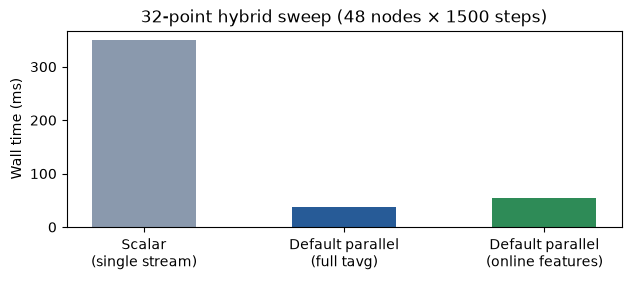

In [2]:
def build_bench_net():
    dt = 0.1
    m_c = MontbrioPazoRoxin(); m_c.configure()
    m_s = SupHopf(a=np.array([-0.1]), omega=np.array([2 * np.pi * 0.01])); m_s.configure()
    sn_c = Subnetwork(name="cortex", model=m_c, scheme=HeunDeterministic(dt=dt), nnodes=32)
    w_cc = sp.csr_matrix((conn.weights[:32, :32] / (conn.weights[:32, :32].max() + 1e-8)).astype(np.float32))
    sn_c.projections = [IntraProjection(source_cvar=c0, target_cvar=c0, weights=w_cc, lengths=sp.csr_matrix((32, 32), dtype=np.float32), cv=5.0, dt=dt, scale=0.05, cfun=Linear())]
    sn_c.configure()
    sn_s = Subnetwork(name="subcortex", model=m_s, scheme=HeunDeterministic(dt=dt), nnodes=16).configure()
    w_cs = sp.csr_matrix((conn.weights[32:48, :32] / (conn.weights[32:48, :32].max() + 1e-8)).astype(np.float32))
    p = InterProjection(source=sn_c, target=sn_s, source_cvar=c0, target_cvar=c0, weights=w_cs, lengths=sp.csr_matrix((16, 32), dtype=np.float32), cv=5.0, dt=dt, scale=0.05, cfun=Linear())
    return NetworkSet(subnets=[sn_c, sn_s], projections=[p]).configure()

ns_bench = build_bench_net()
eta_bench = np.linspace(-5.5, -2.5, 32, dtype=np.float32)
ic_bench = [np.array([np.full((32, 1), 0.1), np.full((32, 1), -1.5)]), np.zeros((2, 16, 1))]

r_scalar = nb.sweep(ns_bench, 1500, width=1, workers=1, initial_states=ic_bench, **{"cortex.eta": eta_bench})
r_batched = nb.sweep(ns_bench, 1500, initial_states=ic_bench, **{"cortex.eta": eta_bench})
r_feat = nb.sweep(ns_bench, 1500, monitor="features", features=["mean", "std", "rms"], initial_states=ic_bench, **{"cortex.eta": eta_bench})

mb_tavg = sum(a.nbytes for a in r_batched.tavg.values()) / 1e6
kb_feat = sum(v.nbytes for d in r_feat.online_features.values() for v in d.values()) / 1e3
print(f"Scalar single-core:     {r_scalar.elapsed*1e3:6.1f} ms | output={mb_tavg:.2f} MB")
print(f"Default batched sweep:  {r_batched.elapsed*1e3:6.1f} ms | speedup={r_scalar.elapsed/r_batched.elapsed:.2f}x")
print(f"Online features stream: {r_feat.elapsed*1e3:6.1f} ms | output={kb_feat:.1f} KB")

fig, ax = plt.subplots(figsize=(6.2, 2.7), layout="constrained")
labels = ["Scalar\n(single stream)", "Default parallel\n(full tavg)", "Default parallel\n(online features)"]
times_ms = [r_scalar.elapsed * 1e3, r_batched.elapsed * 1e3, r_feat.elapsed * 1e3]
ax.bar(labels, times_ms, color=["#8a99ad", "#275b97", "#2e8b57"], width=0.52)
ax.set(ylabel="Wall time (ms)", title="32-point hybrid sweep (48 nodes × 1500 steps)")
plt.show()

## 2. Demo 1 — 1D bifurcation-like sequence (`JansenRit` $\to$ `Generic2dOscillator`)

We sweep `coupling_scale` across 32 points on a coupled 12-node `JansenRit` cortex $\to$ 8-node `Generic2dOscillator` thalamus network and inspect the post-transient response envelope in the thalamus.

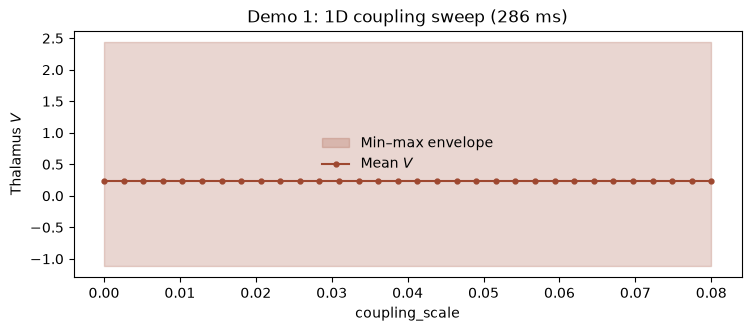

In [3]:
def build_jr_g2d(n_c=12, n_t=8):
    dt = 0.1
    m_c = JansenRit(v0=np.array([6.0]), variables_of_interest=("y0", "y1", "y2")); m_c.configure()
    m_t = Generic2dOscillator(a=np.array([1.0]), tau=np.array([2.0]), variables_of_interest=("V", "W")); m_t.configure()
    s_c = Subnetwork(name="cortex", model=m_c, scheme=HeunStochastic(dt=dt, noise=noise.Additive(nsig=np.array([1e-6]))), nnodes=n_c)
    w_c = sp.csr_matrix((conn.weights[:n_c, :n_c] / (conn.weights[:n_c, :n_c].sum(axis=1, keepdims=True) + 1e-8)).astype(np.float32))
    l_c = sp.csr_matrix(conn.tract_lengths[:n_c, :n_c].astype(np.float32))
    s_c.projections = [IntraProjection(source_cvar=c1, target_cvar=c0, weights=w_c, lengths=l_c, cv=5.0, dt=dt, scale=0.001, cfun=Linear())]
    s_c.configure()
    s_t = Subnetwork(name="thalamus", model=m_t, scheme=HeunStochastic(dt=dt, noise=noise.Additive(nsig=np.array([1e-4]))), nnodes=n_t).configure()
    w_ct = sp.csr_matrix((conn.weights[68:68+n_t, :n_c] / (conn.weights[68:68+n_t, :n_c].max() + 1e-8)).astype(np.float32))
    p = InterProjection(source=s_c, target=s_t, source_cvar=c1, target_cvar=c0, weights=w_ct, lengths=sp.csr_matrix((n_t, n_c), dtype=np.float32), cv=5.0, dt=dt, scale=0.01, cfun=Linear())
    return NetworkSet(subnets=[s_c, s_t], projections=[p]).configure()

ns_d1 = build_jr_g2d()
ic_d1 = [np.zeros((6, 12, 1)), np.zeros((2, 8, 1))]
c_vals = np.linspace(0.0, 0.08, 32, dtype=np.float32)

res_d1 = cpp.sweep(ns_d1, {"coupling_scale": c_vals}, nstep=6000, monitor="tavg", monitor_period=10, chunk_size=10, initial_states=ic_d1, shared_noise=True)
thal_v = res_d1.squeezed("thalamus")[:, 250:, 0, :]
assert np.isfinite(thal_v).all()

fig, ax = plt.subplots(figsize=(7.4, 3.2), layout="constrained")
ax.fill_between(c_vals, thal_v.min(axis=(1, 2)), thal_v.max(axis=(1, 2)), color="#9e4830", alpha=0.22, label="Min–max envelope")
ax.plot(c_vals, thal_v.mean(axis=(1, 2)), "o-", ms=3.5, color="#9e4830", label="Mean $V$")
ax.set(title=f"Demo 1: 1D coupling sweep ({res_d1.elapsed*1e3:.0f} ms)", xlabel="coupling_scale", ylabel="Thalamus $V$")
ax.legend(frameon=False)
plt.show()

## 3. Demo 2 — Sweeping excitability & Power Spectral Density (PSD) variation

Because Welch {term}`PSD <Power spectral density>` (`psd_raw`, `spectrum_stats`, `spectrum_auc`) requires Fourier transforms over a post-burn-in segment, we cannot compute it with `monitor="features"`. Instead, we:
1. Record a downsampled `TemporalAverage` stream (`monitor_period=20, chunk_size=20` at `dt=0.1 ms` $\implies$ `fs = 500 Hz`),
2. Slice off the first `1.0 s` transient and demean the pyramidal postsynaptic potential (`y1 - y2`), and
3. Chain the post-processing feature extractor `features.compute_features` onto that trimmed monitor array.

Demo 2 PSD sweep elapsed: 348 ms | fpeak range: 2.60–8.46 Hz


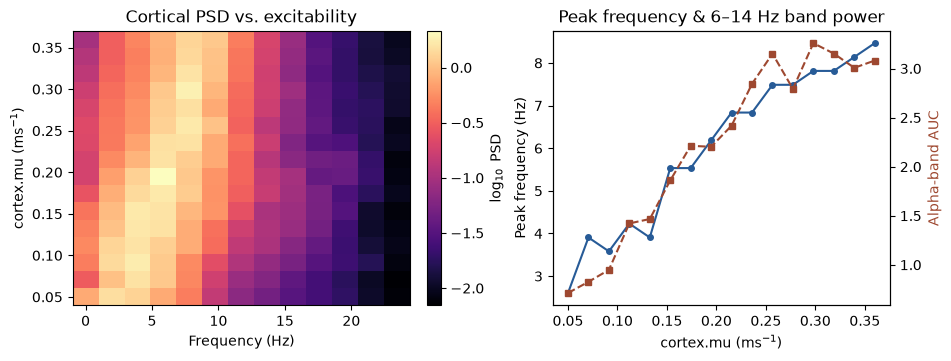

In [4]:
ns_d2 = build_jr_g2d(n_c=6, n_t=4)
ic_d2 = [np.zeros((6, 6, 1)), np.zeros((2, 4, 1))]
mus = np.linspace(0.05, 0.36, 16, dtype=np.float32)

res_d2 = cpp.sweep(
    ns_d2,
    {"cortex.mu": mus},
    nstep=30_000,
    monitor="tavg",
    monitor_period=20,
    chunk_size=20,
    initial_states=ic_d2,
    shared_noise=True,
)
ctx_post = res_d2.squeezed("cortex")[:, 500:, :, :]  # drop first 1.0 s (500 samples)
ts_psp = ctx_post[:, :, 1, :] - ctx_post[:, :, 2, :]  # pyramidal potential y1 - y2
ts_dm = ts_psp - ts_psp.mean(axis=1, keepdims=True)
assert np.isfinite(ts_dm).all()

spec = dict(feat.compute_features(np.moveaxis(ts_dm, 1, 0), ["psd_raw", "spectrum_stats", "spectrum_auc"], fs=500.0, lo=6.0, hi=14.0))
psd_arr = spec["psd_raw"]          # row 0 = freqs, rows 1.. = (sweep, node, n_freq)
freqs = psd_arr[0, 0, :]
psd_mean = psd_arr[1:].mean(axis=1)  # mean over nodes -> (n_sweep, n_freq)
fpeak = spec["spectrum_stats"][1].mean(axis=1)
alpha_auc = spec["spectrum_auc"].mean(axis=1)
assert np.ptp(fpeak) > 2.0, f"Expected clear peak-frequency shift, got {fpeak}"
print(f"Demo 2 PSD sweep elapsed: {res_d2.elapsed*1e3:.0f} ms | fpeak range: {fpeak.min():.2f}–{fpeak.max():.2f} Hz")

fmask = freqs <= 25.0
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.4, 3.5), layout="constrained")
pcm = ax1.pcolormesh(freqs[fmask], mus, np.log10(psd_mean[:, fmask] + 1e-12), shading="auto", cmap="magma")
ax1.set(title="Cortical PSD vs. excitability", xlabel="Frequency (Hz)", ylabel="cortex.mu (ms$^{-1}$)")
fig.colorbar(pcm, ax=ax1, label="$\\log_{10}$ PSD")

ax2.plot(mus, fpeak, "o-", color="#275b97", ms=4, label="Peak frequency (Hz)")
ax2.set(title="Peak frequency & 6–14 Hz band power", xlabel="cortex.mu (ms$^{-1}$)", ylabel="Peak frequency (Hz)")
ax2r = ax2.twinx()
ax2r.plot(mus, alpha_auc, "s--", color="#9e4830", ms=4, label="6–14 Hz AUC")
ax2r.set_ylabel("Alpha-band AUC", color="#9e4830")
plt.show()

## 4. Demo 3 — Sweeping excitability & Balloon–Windkessel BOLD FC

Here we partition 16 regions of `connectivity_76.zip` into a **multirate** hybrid network—a 10-region cortical subnetwork (`dt=0.5 ms`) reciprocally coupled to a 6-region subcortical subnetwork (`dt=1.0 ms`), both running stochastic `SupHopf` oscillators. Below we assemble the partitioned network cleanly first, then attach the biophysical `BalloonWindkessel` monitor in its own cell.

In [5]:
n_ctx, n_sub = 10, 6
W16 = conn.weights[:16, :16].astype(np.float32)
L16 = conn.tract_lengths[:16, :16].astype(np.float32)
W16 = W16 / (W16.sum(axis=1).max() + 1e-8)

slices = {"cortex": slice(0, n_ctx), "subcortex": slice(n_ctx, n_ctx + n_sub)}

def make_hopf_subnet(name, sl, dt_val, a_init, f_hz, seed):
    model = SupHopf(a=np.array([a_init]), omega=np.array([2 * np.pi * f_hz]), variables_of_interest=("x",))
    model.configure()
    scheme = HeunStochastic(dt=dt_val, noise=noise.Additive(nsig=np.array([5e-3]), noise_seed=seed))
    sn = Subnetwork(name=name, model=model, scheme=scheme, nnodes=sl.stop - sl.start, node_indices=np.arange(sl.start, sl.stop))
    sn.projections = [
        IntraProjection(
            source_cvar=c0, target_cvar=c0,
            weights=sp.csr_matrix(W16[sl, sl]), lengths=sp.csr_matrix(L16[sl, sl]),
            cv=10.0, dt=dt_val, scale=0.25, cfun=Linear(),
        )
    ]
    return sn.configure()

cortex_bw = make_hopf_subnet("cortex", slices["cortex"], dt_val=0.5, a_init=-0.1, f_hz=0.002, seed=42)
subcortex_bw = make_hopf_subnet("subcortex", slices["subcortex"], dt_val=1.0, a_init=-0.05, f_hz=0.0015, seed=43)

def inter_proj(src, tgt):
    s_sl, t_sl = slices[src.name], slices[tgt.name]
    return InterProjection(
        source=src, target=tgt, source_cvar=c0, target_cvar=c0,
        weights=sp.csr_matrix(W16[t_sl, s_sl]), lengths=sp.csr_matrix(L16[t_sl, s_sl]),
        cv=10.0, dt=float(src.scheme.dt), scale=0.25, cfun=Linear(),
    )

ns_bw = NetworkSet(subnets=[cortex_bw, subcortex_bw], projections=[inter_proj(cortex_bw, subcortex_bw), inter_proj(subcortex_bw, cortex_bw)]).configure()

### Configure `BalloonWindkessel`, run the sweep, and chain FC + BOLD features

We pass `bw={"global": bw_mon}` with `monitor="none"` so only the biophysical BOLD stream (`(n_sweep, n_bold_t, 1, 16, 1)`) is returned, using `shared_noise=True` for common random numbers across `cortex.a`. After discarding the first `15 s` hemodynamic transient, we compute **both**:
1. Regional Pearson **functional connectivity (FC)** matrices and FC–SC alignment across `cortex.a`, and
2. Post-processing BOLD features (`std` and `0.01–0.1 Hz` `spectrum_auc`) by chaining `features.compute_features` directly onto the BW BOLD time series!

:::{note} Global vs. local `BalloonWindkessel` placement
`bw={"global": bw_mon}` gathers observations across subnetworks when they share the same observed variable names, `n_modes == 1`, disjoint `node_indices`, and a master `dt` dividing `10 ms` (satisfied here). When combining model classes with different VOI names (e.g., `JansenRit` + `MontbrioPazoRoxin`), pass `bw={"local": {"cortex": bw_mon, "subcortex": bw_mon}}` instead.
:::

Demo 3 BW FC sweep elapsed: 727 ms | mean FC: 0.31–0.80 | BOLD std: 0.00010–0.00256


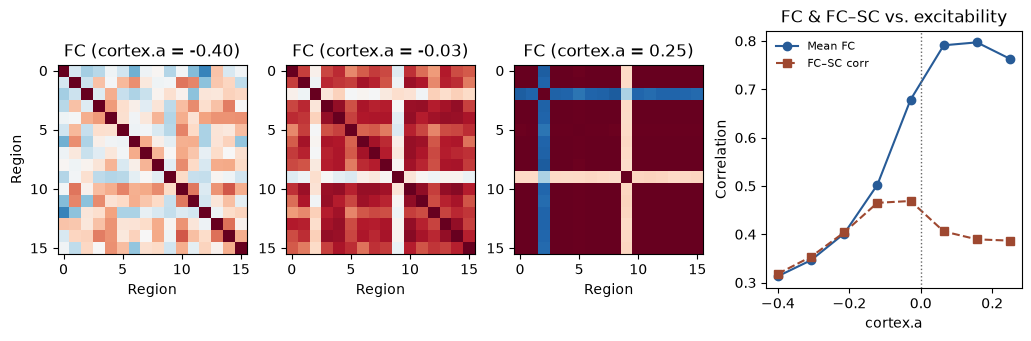

In [6]:
bw_mon = BalloonWindkessel(
    period=1000.0,                   # 1.0 s TR (100 complete 10 ms drive windows)
    variables_of_interest=c0,        # observed VOI index 0 ("x")
    drive_baseline=0.0,              # resting observation baseline
    drive_scale=0.5,                 # drive calibration [s^-2 per unit]
)

a_vals = np.linspace(-0.4, 0.25, 8, dtype=np.float32)
ic_bw = [np.zeros((2, n_ctx, 1)), np.zeros((2, n_sub, 1))]

res_bw = cpp.sweep(
    ns_bw,
    {"cortex.a": a_vals},
    nstep=120_000,                   # 60 s at master dt = 0.5 ms
    monitor="none",
    shared_noise=True,
    initial_states=ic_bw,
    bw={"global": bw_mon},
)
t_bw, y_bw = res_bw.bw_global
bold = y_bw[:, 15:, 0, :, 0]        # drop first 15 s hemodynamic burn-in -> (8, 45, 16)
assert np.isfinite(bold).all() and bold.shape == (8, 45, 16)

# 1) Chain post-processing BOLD features directly onto the BW output (time axis first)
bold_feats = dict(feat.compute_features(np.moveaxis(bold, 1, 0), ["std", "spectrum_auc"], fs=1.0, lo=0.01, hi=0.1))
bold_std = bold_feats["std"].mean(axis=1)

# 2) Compute pairwise BOLD FC and FC-SC correlation
triu = np.triu_indices(16, k=1)
sc_vec = W16[triu]
fcs = np.array([np.corrcoef(bold[i].T) for i in range(len(a_vals))])
mean_fc = np.array([fc[triu].mean() for fc in fcs])
fc_sc = np.array([np.corrcoef(fc[triu], sc_vec)[0, 1] for fc in fcs])
assert np.ptp(mean_fc) > 0.3
print(f"Demo 3 BW FC sweep elapsed: {res_bw.elapsed*1e3:.0f} ms | mean FC: {mean_fc.min():.2f}–{mean_fc.max():.2f} | BOLD std: {bold_std.min():.5f}–{bold_std.max():.5f}")

fig = plt.figure(figsize=(10.2, 3.3), layout="constrained")
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.35])
for k, idx in enumerate([0, 4, 7]):
    ax = fig.add_subplot(gs[0, k])
    ax.imshow(fcs[idx], vmin=-0.5, vmax=1.0, cmap="RdBu_r")
    ax.set(title=f"FC (cortex.a = {a_vals[idx]:.2f})", xlabel="Region", ylabel="Region" if k == 0 else "")
ax_curve = fig.add_subplot(gs[0, 3])
ax_curve.plot(a_vals, mean_fc, "o-", color="#275b97", label="Mean FC")
ax_curve.plot(a_vals, fc_sc, "s--", color="#9e4830", label="FC–SC corr")
ax_curve.axvline(0.0, color="#666", ls=":", lw=1.0)
ax_curve.set(title="FC & FC–SC vs. excitability", xlabel="cortex.a", ylabel="Correlation")
ax_curve.legend(frameon=False, fontsize=8)
plt.show()

## 5. Demo 4 — 3D Monte Carlo Sobol sweep (`MontbrioPazoRoxin` + `SupHopf`)

Finally, we run a 64-point 3D Sobol sweep (`grid=False`) over `cortex.eta`, `subcortex.a`, and `coupling_scale` on our heterogeneous `MontbrioPazoRoxin` + `SupHopf` network using `monitor="features"` so no intermediate trajectories are allocated.

Demo 4 3D Sobol streaming sweep elapsed: 56.5 ms


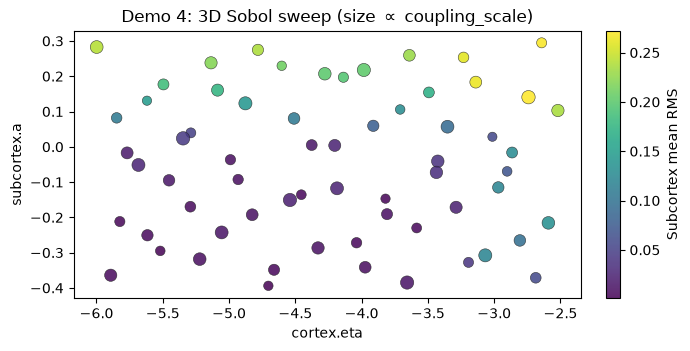

In [7]:
u_sobol = qmc.Sobol(d=3, scramble=True, seed=123).random_base2(m=6)
X3 = qmc.scale(u_sobol, [-6.0, -0.4, 0.02], [-2.5, 0.3, 0.3]).astype(np.float32)

res_mc = nb.sweep(
    ns_bench,
    nstep=1200,
    monitor="features",
    features=["mean", "std", "rms", "zero_crossing"],
    initial_states=ic_bench,
    **{
        "cortex.eta": X3[:, 0],
        "subcortex.a": X3[:, 1],
        "coupling_scale": X3[:, 2],
    },
)
sub_rms_mc = res_mc.features(["rms"], svar=0, subnet="subcortex")["rms"].mean(axis=1)
assert np.isfinite(sub_rms_mc).all()
print(f"Demo 4 3D Sobol streaming sweep elapsed: {res_mc.elapsed*1e3:.1f} ms")

fig, ax = plt.subplots(figsize=(6.8, 3.4), layout="constrained")
sc = ax.scatter(X3[:, 0], X3[:, 1], c=sub_rms_mc, s=40 + 180 * X3[:, 2], cmap="viridis", alpha=0.85, edgecolors="#222", lw=0.4)
ax.set(title="Demo 4: 3D Sobol sweep (size $\\propto$ coupling_scale)", xlabel="cortex.eta", ylabel="subcortex.a")
fig.colorbar(sc, ax=ax, label="Subcortex mean RMS")
plt.show()

## Next steps

- Architectural deep dive on SIMD vectorization, Philox RNG, and `kmon` engines: [C++ Hybrid Backend](../hpc/cpp-hybrid-backend.md).
- Standalone Balloon–Windkessel demos: [Regional Balloon–Windkessel](../../demos/cpp_hybrid_balloon_windkessel.ipynb) and [Multirate BW sweep](../../demos/cpp_hybrid_multirate_bw_sweep.ipynb).
- Full backend capability matrix: [Backends and parameter sweeps](../hybrid/hybrid-backends-and-sweeps.md).